In [11]:
!pip install loguru
!pip install pyment

2026-11-17 23:06:31.465 +04:00 | DEBUG    | __main__:<module>:307 - debug
2026-11-17 23:06:31.466 +04:00 | INFO     | __main__:comparison:273 - epsilon-greedy experiment
2026-11-17 23:06:31.694 +04:00 | INFO     | __main__:report:217 - [EpsilonGreedy(epsilon_init=0.963)] cumulative reward: 80019.2536
2026-11-17 23:06:31.695 +04:00 | INFO     | __main__:report:218 - [EpsilonGreedy(epsilon_init=0.963)] cumulative regret: 16.0000
2026-11-17 23:06:31.695 +04:00 | INFO     | __main__:comparison:278 - thompson sampling experiment
2026-11-17 23:06:31.799 +04:00 | INFO     | __main__:report:266 - [ThompsonSampling] cumulative reward: 78965.2642
2026-11-17 23:06:31.800 +04:00 | INFO     | __main__:report:267 - [ThompsonSampling] cumulative regret: 960.0000
2026-11-17 23:06:31.881 +04:00 | INFO     | __main__:comparison:298 - stored experimental logs in 'bandit_exp.csv'


--- EpsilonGreedy(epsilon_init=0.963) Report ---
cumulative reward: 80019.2536
cumulative regret: 16.0000
--- ThompsonSampling Report ---
cumulative reward: 78965.2642
cumulative regret: 960.0000


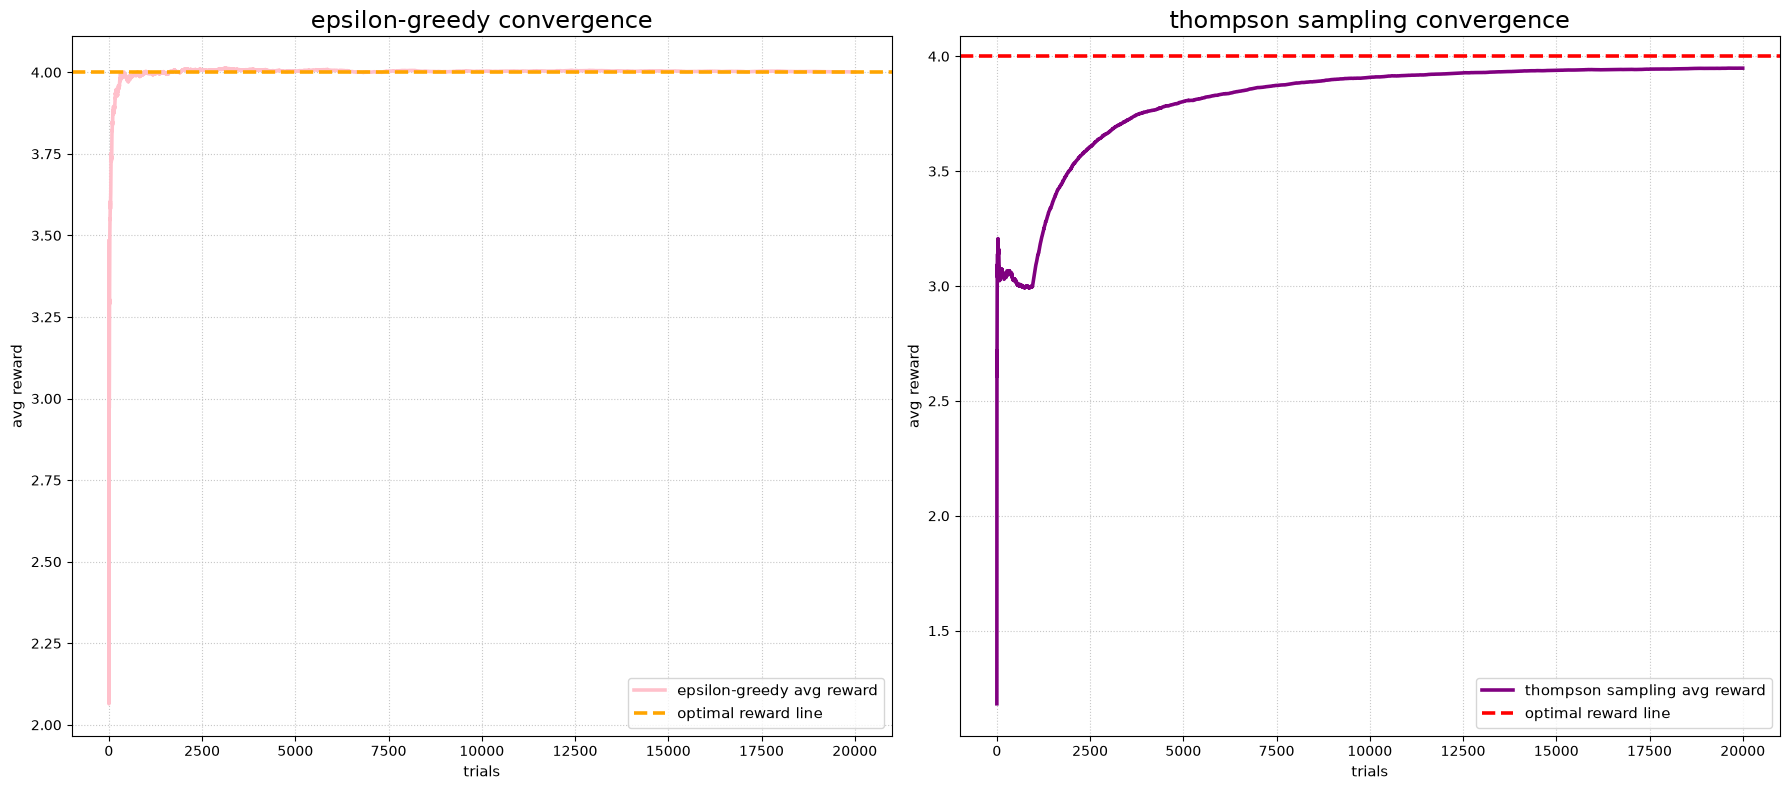

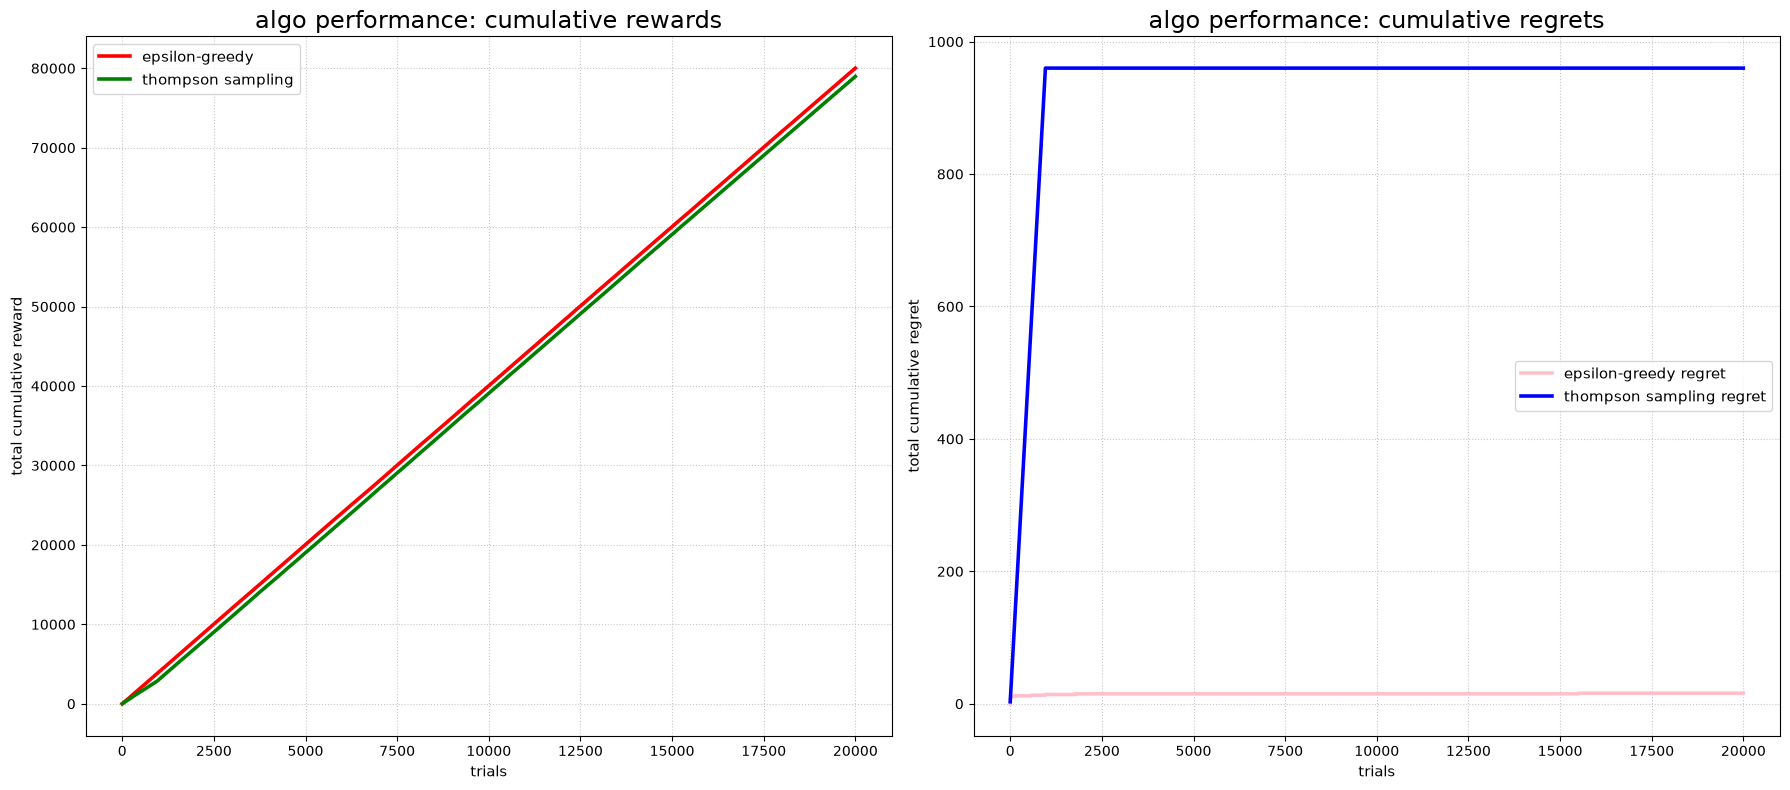

In [45]:
"""
 using epsilon-greedy and thompson sampling for multi-armed bandits with gaussian rewards.
"""

from abc import ABC, abstractmethod
from loguru import logger
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BANDIT_REWARD = [1, 2, 3, 4]
NUM_TRIALS = 20000
EPSILON_INIT = 0.963
PRECISION = 3.369  


class Bandit(ABC):
    ##==== DO NOT REMOVE ANYTHING FROM THIS CLASS ====##

    @abstractmethod
    def __init__(self, p):
        pass

    @abstractmethod
    def __repr__(self):
        pass

    @abstractmethod
    def pull(self):
        pass

    @abstractmethod
    def update(self, x):
        pass

    @abstractmethod
    def experiment(self):
        pass

    @abstractmethod
    def report(self):
        # store data in csv
        # print average reward (use f strings to make it informative)
        # print average regret (use f strings to make it informative)
        pass

#--------------------------------------#

class Visualization():
    """visualizations and comparisons of our algos"""

    def plot1(self, eps_greet_reward, ts_rewards, bandit_means):
        """lets visualize learning process"""
        plt.figure(figsize=(18, 8)) 
        
        #epsilon-greedy avg
        plt.subplot(1, 2, 1)
        eg_cum_avg = np.cumsum(eps_greet_reward) / (np.arange(len(eps_greet_reward)) + 1)
        plt.plot(eg_cum_avg, label='epsilon-greedy avg reward', color='pink', linewidth=2.58)
        plt.axhline(max(bandit_means), color='orange', linestyle='--', label='optimal reward line', linewidth=2.58)
        plt.title("epsilon-greedy convergence", fontsize=17)
        plt.xlabel("trials", fontsize=11) 
        plt.ylabel("avg reward", fontsize=11)
        plt.legend(fontsize=11) 
        plt.grid(True, linestyle=':', alpha=0.7)

        #thompson sampling avg 
        plt.subplot(1, 2, 2) 
        ts_cum_avg = np.cumsum(ts_rewards) / (np.arange(len(ts_rewards)) + 1)
        plt.plot(ts_cum_avg, label='thompson sampling avg reward', color='purple', linewidth=2.58)
        plt.axhline(max(bandit_means), color='red', linestyle='--', label='optimal reward line', linewidth=2.58)
        plt.title("thompson sampling convergence", fontsize=17) 
        plt.xlabel("trials", fontsize=11)
        plt.ylabel("avg reward", fontsize=11) 
        plt.legend(fontsize=11)
        plt.grid(True, linestyle=':', alpha=0.7)

        plt.tight_layout()
        plt.savefig("learn_process.png")
        plt.show()

    def plot2(self, eps_greet_reward, ts_rewards, eg_choices, ts_choices):
        """lets compare cumulative reward and regret"""
        eg_cum_reward = np.cumsum(eps_greet_reward)
        ts_cum_reward = np.cumsum(ts_rewards)
        
        optimal_per_trial = max(BANDIT_REWARD)

        eg_regret = np.cumsum([
            optimal_per_trial - BANDIT_REWARD[j]
            for j in eg_choices
        ])

        ts_regret = np.cumsum([
            optimal_per_trial - BANDIT_REWARD[j]
            for j in ts_choices
        ])

        plt.figure(figsize=(18, 8)) 
        
        #cumulative reward compare
        plt.subplot(1, 2, 1)
        plt.plot(eg_cum_reward, label='epsilon-greedy', color='red', linewidth=2.58)
        plt.plot(ts_cum_reward, label='thompson sampling', color='green', linewidth=2.58)
        plt.title("algo performance: cumulative rewards", fontsize=17) 
        plt.xlabel("trials", fontsize=11)
        plt.ylabel("total cumulative reward", fontsize=11) 
        plt.legend(fontsize=11) 
        plt.grid(True, linestyle=':', alpha=0.7)

        #cumulative regret comparison 
        plt.subplot(1, 2, 2) 
        plt.plot(eg_regret, label='epsilon-greedy regret', color='pink', linewidth=2.58)
        plt.plot(ts_regret, label='thompson sampling regret', color='blue', linewidth=2.58)
        plt.title("algo performance: cumulative regrets", fontsize=17) 
        plt.xlabel("trials", fontsize=11) 
        plt.ylabel("total cumulative regret", fontsize=11) 
        plt.legend(fontsize=11) 
        plt.grid(True, linestyle=':', alpha=0.7)

        plt.tight_layout()
        plt.savefig("comparison.png")
        plt.show()

#--------------------------------------#

class GaussianBanditArm:
    """lets use helper class representing a single bandit arm with gaussian rewards"""
    def __init__(self, true_mean, tau):
        self.true_mean = true_mean
        self.tau = tau
        self.m = 0.0
        self.lambda_ = 1.0
        self.sum_x = 0.0
        self.N = 0

    def pull(self):
        return np.random.randn() / np.sqrt(self.tau) + self.true_mean

    def sample_posterior(self):
        return np.random.randn() / np.sqrt(self.lambda_) + self.m

    def update(self, x):
        self.lambda_ += self.tau
        self.sum_x += x
        self.m = (self.tau * self.sum_x) / self.lambda_
        self.N += 1


class EpsilonGreedy(Bandit):
    """epsilon-greedy algorithm implementation inheriting from bandit"""
    
    def __init__(self, p):
        self.true_means = p
        self.tau = PRECISION
        self.num_trials = NUM_TRIALS
        self.initial_eps = EPSILON_INIT
        self.bandits = [GaussianBanditArm(m, self.tau) for m in self.true_means]
        self.rewards = np.zeros(self.num_trials)
        self.choices = []

    def __repr__(self):
        return f"EpsilonGreedy(epsilon_init={self.initial_eps})"

    def pull(self, j=None):
        if j is not None:
            return self.bandits[j].pull()
        return [b.pull() for b in self.bandits]

    def update(self, j, x=None):
        if x is not None:
            self.bandits[j].update(x)

    def experiment(self):
        for i in range(self.num_trials):
            t = i + 1
            eps = self.initial_eps / t 
            
            if np.random.random() < eps:
                j = np.random.randint(len(self.bandits))
            else:
                # optimial for unpulled arms 
                values = [
                    b.sum_x / b.N if b.N > 0 else float('inf')
                    for b in self.bandits
                ]

                # Select randomly among unpulled arms first
                if any(b.N == 0 for b in self.bandits):
                    unpulled = [
                        j for j, b in enumerate(self.bandits)
                        if b.N == 0
                    ]
                    j = np.random.choice(unpulled)
                else:
                    best_arms = np.flatnonzero(values == np.max(values))
                    j = np.random.choice(best_arms)
            
            x = self.pull(j)
            self.rewards[i] = x
            self.update(j, x)
            self.choices.append(j)
        return self.rewards, self.choices

    def report(self):
        our_reward = self.rewards.sum()

        total_regret = sum(
            max(self.true_means) - self.true_means[j]
            for j in self.choices
        )
        
        print(f"--- {self.__repr__()} Report ---")
        print(f"cumulative reward: {our_reward:.4f}")
        print(f"cumulative regret: {total_regret:.4f}")
        
        logger.info(f"[{self.__repr__()}] cumulative reward: {our_reward:.4f}")
        logger.info(f"[{self.__repr__()}] cumulative regret: {total_regret:.4f}")
        return our_reward, total_regret


class ThompsonSampling(Bandit):
    """thompson sampling algorithm implementation inheriting from bandit"""
    
    def __init__(self, p):
        self.true_means = p
        self.tau = PRECISION
        self.num_trials = NUM_TRIALS
        self.bandits = [GaussianBanditArm(m, self.tau) for m in self.true_means]
        self.rewards = np.zeros(self.num_trials)
        self.choices = []

    def __repr__(self):
        return "ThompsonSampling"

    def pull(self, j=None):
        if j is not None:
            return self.bandits[j].pull()
        return [b.pull() for b in self.bandits]

    def update(self, j, x=None):
        if x is not None:
            self.bandits[j].update(x)

    def experiment(self):
        for i in range(self.num_trials):
            j = np.argmax([b.sample_posterior() for b in self.bandits])
            x = self.pull(j)
            self.rewards[i] = x
            self.update(j, x)
            self.choices.append(j)
        return self.rewards, self.choices

    def report(self):
        our_reward = self.rewards.sum()

        total_regret = sum(
            max(self.true_means) - self.true_means[j]
            for j in self.choices
        )
        
        print(f"--- {self.__repr__()} Report ---")
        print(f"cumulative reward: {our_reward:.4f}")
        print(f"cumulative regret: {total_regret:.4f}")
        
        logger.info(f"[{self.__repr__()}] cumulative reward: {our_reward:.4f}")
        logger.info(f"[{self.__repr__()}] cumulative regret: {total_regret:.4f}")
        return our_reward, total_regret


def comparison():
    """lets run experiments for both algorithms and prints reports,save to CSV, and visualise"""
    logger.info("epsilon-greedy experiment")
    eg = EpsilonGreedy(BANDIT_REWARD)
    eps_greet_reward, eg_choices = eg.experiment()
    eg.report()

    logger.info("thompson sampling experiment")
    ts = ThompsonSampling(BANDIT_REWARD)
    ts_rewards, ts_choices = ts.experiment()
    ts.report()

    #CSV 
    df_eg = pd.DataFrame({
        'Bandit': eg_choices,
        'Reward': eps_greet_reward,
        'Algorithm': 'EpsilonGreedy'
    })
    
    df_ts = pd.DataFrame({
        'Bandit': ts_choices,
        'Reward': ts_rewards,
        'Algorithm': 'ThompsonSampling'
    })
    
    df_all = pd.concat([df_eg, df_ts], ignore_index=True)
    df_all.to_csv('bandit_exp.csv', index=False)
    logger.info("stored experimental logs in 'bandit_exp.csv'")

    #visualization
    viz = Visualization()
    viz.plot1(eps_greet_reward, ts_rewards, BANDIT_REWARD)
    viz.plot2(eps_greet_reward, ts_rewards, eg_choices, ts_choices)


if __name__ == '__main__':
    logger.debug("debug")
    comparison()

In [ ]:
#We can add a third algorithm called UCB1. Imagine you are a rapper launching a new song and using a small budget to run YouTube ads. You create four different ten-second video teasers to see which one brings in the most streams. Testing these manually wastes money on bad clips, and the other methods still have room for improvement.

#While epsilon-greedy relies on random guesses and thompson sampling uses probabilities, UCB1 acts like an optimistic explorer. It looks at both the average success of a clip and how sure we are about those results. If a teaser clip has only been tested a few times, UCB1 gives it a helpful boost just in case it is actually the best choice.

#To add this to our code, we can create a new UCB1 class and include its results in our comparison charts. 
